# MediCheck-GPT

This notebook runs my whole project end to end on a Colab T4. Data and checkpoints are saved to my Drive as they are produced, and every stage that has already finished is skipped, so I can pick up wherever a session stopped.

## 0. Setup

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv   # confirm the T4 is attached

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
from google.colab import drive
drive.mount('/content/drive')                     # the raw CMS file lives in my Drive
ROOT = '/content/drive/MyDrive/build-transformer'   # same folder as 01_data.ipynb

Mounted at /content/drive


In [3]:
%cd /content
!rm -rf /content/medicheck-gpt                       # start from a clean copy of the code
!git clone https://github.com/cece15/medicheck-gpt.git /content/medicheck-gpt
%cd /content/medicheck-gpt
!pip install -q -r requirements.txt
# data and checkpoints live in my Drive, so nothing is lost if the session disconnects
!mkdir -p "$ROOT/medicheck/data" "$ROOT/medicheck/checkpoints"
!ln -sfn "$ROOT/medicheck/data" data && ln -sfn "$ROOT/medicheck/checkpoints" checkpoints && ls -l
!git log --oneline -1                               # the version of the code this run used

/content
Cloning into '/content/medicheck-gpt'...
remote: Enumerating objects: 148, done.
remote: Counting objects: 100% (148/148), done.
remote: Compressing objects: 100% (97/97), done.
remote: Total 148 (delta 103), reused 83 (delta 45), pack-reused 0 (from 0)
Receiving objects: 100% (148/148), 197.00 KiB | 1.54 MiB/s, done.
Resolving deltas: 100% (103/103), done.
/content/medicheck-gpt
total 72
lrwxrwxrwx 1 root root    62 Nov 15 00:30 checkpoints -> /content/drive/MyDrive/build-transformer/medicheck/checkpoints
lrwxrwxrwx 1 root root    55 Nov 15 00:30 data -> /content/drive/MyDrive/build-transformer/medicheck/data
-rwxr-xr-x 1 root root 17314 Nov 15 00:30 gpt.py
drwxr-xr-x 2 root root  4096 Nov 15 00:30 notebooks
-rw-r--r-- 1 root root 18934 Nov 15 00:30 README.md
-rw-r--r-- 1 root root   166 Nov 15 00:30 requirements.txt
drwxr-xr-x 2 root root  4096 Nov 15 00:30 src
drwxr-xr-x 2 root root  4096 Nov 15 00:30 tests
-rw-r--r-- 1 root root 10835 Nov 15 00:30 WALKTHROUGH.md
e23980a (H

## 1. Data

I turn each row of the CMS file into one English sentence and split the data by hospital, not by row: 160 hospitals for training, 20 for validation and 20 for testing. The test hospitals never appear in training, so the scores show whether the model learned what a record looks like rather than memorizing one hospital's lines.

In [4]:
import os
if not os.path.exists('data/processed/test.txt'):
    !python gpt.py --input "$ROOT/data/raw/MUP_INP_RY26_P03_V10_DY24_PrvSvc.CSV" --prepare data/processed
!head -c 600 data/processed/train.txt


Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 291 (HEART FAILURE AND SHOCK WITH MCC) for 20 discharges: covered charges $19134, total payment $9134, Medicare payment $7828.
Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 871 (SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITH MCC) for 53 discharges: covered charges $28663, total payment $12681, Medicare payment $10761.
Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 872 (SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITHOUT MCC) for 21 discharges: covered charges $19285, total payment $8101, Medicare p

## 2. Baseline: bigram

The bigram predicts the next character from the current one only. If the transformer can't beat this, it hasn't learned anything.

In [5]:
if not os.path.exists('checkpoints/bigram.pth'):
    !python gpt.py --input data/processed --train checkpoints/bigram.pth --model bigram --context_size 8 --lr 1e-2 --steps 3000

## 3. Transformer

4 layers, 4 heads, 128-dimensional embeddings and a 271-character window, which is the longest record plus its two newlines, so the model always sees one whole record. My first prototype overfit after about 1,500 steps, so here I use a cosine learning-rate schedule with warmup, weight decay and early stopping.

In [6]:
if not os.path.exists('checkpoints/gpt.pth'):
    !python gpt.py --input data/processed --train checkpoints/gpt.pth --steps 10000 --eval_every 500 --patience 4

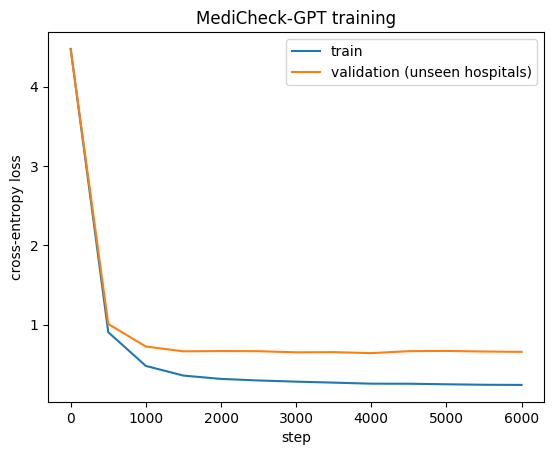

In [7]:
# loss curve
import json, matplotlib.pyplot as plt
h = json.load(open('checkpoints/gpt_history.json'))
plt.plot([r['step'] for r in h], [r['train'] for r in h], label='train')
plt.plot([r['step'] for r in h], [r['val'] for r in h], label='validation (unseen hospitals)')
plt.xlabel('step'); plt.ylabel('cross-entropy loss'); plt.legend(); plt.title('MediCheck-GPT training')
plt.savefig('checkpoints/loss_curve.png', dpi=200, bbox_inches='tight'); plt.show()

## 3a. Model size

Same data, same seed, same early stopping; only the size and dropout change. I trained the base model three times in total, which is how I could tell real differences from run-to-run noise.

In [8]:
# smaller and larger than the base model (base = 4 layers, 4 heads, 128-dim, already trained above)
if not os.path.exists('checkpoints/gpt_large.pth'):
    !python gpt.py --input data/processed --train checkpoints/gpt_small.pth --n_layer 2 --n_head 2 --n_embd 64 --steps 6000
    !python gpt.py --input data/processed --train checkpoints/gpt_large.pth --n_layer 6 --n_head 6 --n_embd 192 --dropout 0.2 --steps 6000

In [9]:
# which size does best on hospitals it has never seen?
import math, torch, pandas as pd
from src.model import build, count_params
rows = []
for name in ['gpt_small', 'gpt', 'gpt_large']:
    ck = torch.load(f'checkpoints/{name}.pth', map_location='cpu')
    best = min(ck['history'], key=lambda r: r['val'])            # the checkpoint holds the best evaluation
    rows.append({'model': name, **{k: ck['config'][k] for k in ['n_layer', 'n_head', 'n_embd', 'dropout']},
                 'parameters': count_params(build(ck['kind'], **ck['config'])),
                 'best_step': best['step'], 'best_val_loss': round(best['val'], 4),
                 'val_perplexity': round(math.exp(best['val']), 3), 'seconds': best['seconds']})
pd.DataFrame(rows)

,model,n_layer,n_head,n_embd,dropout,parameters,best_step,best_val_loss,val_perplexity,seconds
0,gpt_small,2,2,64,0.1,126989,3500,0.7434,2.103,77
1,gpt,4,4,128,0.1,846285,4000,0.6403,1.897,331
2,gpt_large,6,6,192,0.2,2747789,1500,0.6341,1.885,302


## 3b. LLM teacher

Kacper suggested having an LLM write reference sentences and training my small model to reproduce them. I use Qwen2.5-1.5B-Instruct on the T4. In my first attempt the LLM invented numbers in 15% of sentences, and many of the sentences that passed attached real numbers to the wrong label. So now Python computes every number, the LLM gets each fact as a full phrase with one example sentence, and any sentence with an invented or mislabeled number is rejected. A rejected record gets one retry; if it fails again, I leave it out.

In [10]:
import os
if not os.path.exists('data/described_v2/test.txt'):       # the teacher is the slow step, so it only runs once
    !python gpt.py --input data/processed --teacher data/described_v2 --limit 5000
print(open('data/described_v2/teacher_report.json').read())
!head -c 1200 data/described_v2/train.txt

{
 "train": {
  "records": 5000,
  "kept": 3328,
  "rejected": {
   "invented_number": 928,
   "wrong_label": 2201,
   "format": 0,
   "too_long": 0
  }
 },
 "val": {
  "records": 987,
  "kept": 594,
  "rejected": {
   "invented_number": 205,
   "wrong_label": 459,
   "format": 0,
   "too_long": 0
  }
 },
 "test": {
  "records": 762,
  "kept": 518,
  "rejected": {
   "invented_number": 159,
   "wrong_label": 293,
   "format": 0,
   "too_long": 0
  }
 }
}

Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 871 (SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITH MCC) for 53 discharges: covered charges $28663, total payment $12681, Medicare payment $10761. || Corewell Health Zeeland Hospital treated 53 Medicare patients with septicemia or severe sepsis without mechanical ventilation for more than 96 hours, averaging a bill of $28,663 but receiving $12,681 in total payments, with Medicare covering 85% of those payments.
Promedica Charles And Virginia Hickman Hospital in Adrian, 

## 3c. Student, version 2: pre-train, then fine-tune

My first student trained from scratch on random windows and learned the teacher's style while ignoring the record. This version starts from my record model, which already knows what records look like, and fine-tunes on whole examples with the loss counted on the explanation only. Validation loss here covers the explanation only, so it can't be compared with the first student's.

In [11]:
if not os.path.exists('checkpoints/explain_v2.pth'):
    !python gpt.py --input data/described_v2 --train checkpoints/explain_v2.pth --init_from checkpoints/gpt.pth --steps 4000 --eval_every 250 --patience 4

In [12]:
# the record goes in as a Python argument because the shell would treat its '$' signs as variables
import subprocess
rec = open('data/processed/test.txt').read().split('\n')[1]
print('record :', rec)
print(subprocess.run(['python', 'gpt.py', '--eval', 'checkpoints/explain_v2.pth', '--prompt', rec, '--n', '3', '--temperature', '0.5'],
                     capture_output=True, text=True).stdout)

record : Munson Healthcare Grayling Hospital in Grayling, MI billed DRG 177 (RESPIRATORY INFECTIONS AND INFLAMMATIONS WITH MCC) for 27 discharges: covered charges $37016, total payment $15466, Medicare payment $14681.
device: cuda
Munson Healthcare Otsego Memorial Hospital in Gaylord, MI treated 30 Medicare patients with acute myocardial infarction who were discharged alive with complications; they were billed $28,233 on average but were paid $12,017 in total by Medicare, receiving 89% of the payment. 

Munson Healthcare Otsego Memorial Hospital treated 32 Medicare patients with pulmonary embolism or acute complex or ean cor coveredures, averaging a bill of $45,846, but received $11,219 in total payments, with Medicare covering 84% of the cost. 

Munson Healthcare's Cadillac Hospital treated 11 Medicare patients with carrdiac arrhythmia and conduction disorders, averaging a bill of $47,266 per patient, but received $11,099 in total payments, with Medicare covering 81% of the amount. 



## 3d. Student, version 3: placeholders

Version 2 wrote like the teacher but filled in numbers from memory: none of its sentences used the record's numbers. A model this small doesn't copy digits from its input. So I replace the record's own values in the teacher's sentences with placeholders (`{BILL}`, `{TOTAL}`, `{HOSPITAL}` and so on). The student learns where each placeholder goes, and code puts the real values back. This is delexicalisation, the usual way data-to-text systems keep numbers faithful.

In [13]:
if not os.path.exists('checkpoints/explain_v3.pth'):
    !python gpt.py --input data/described_v2 --train checkpoints/explain_v3.pth --init_from checkpoints/gpt.pth --delex --steps 4000 --eval_every 250 --patience 4
print(subprocess.run(['python', 'gpt.py', '--eval', 'checkpoints/explain_v3.pth', '--prompt', rec, '--n', '3', '--temperature', '0.5'],
                     capture_output=True, text=True).stdout)

device: cuda
Munson Healthcare Grayling Hospital in Grayling, MI treated 27 Medicare patients with kidney and urinary tract isues, averaging a bill of $37,016, but received $15,466 in total payments, with Medicare covering 95% of the reimbursement. 

Munson Healthcare Grayling Hospital in Grayling, MI billed $37,016 on average for 27 Medicare patients with cardiac arrhythmias and conduction disorders, receiving $15,466 in total payments, with Medicare covering 95% of the cost. 

Munson Healthcare Grayling Hospital in Grayling, MI, treated 27 Medicare patients with respiratory infections and inflammations, averaging a bill of $37,016 but receiving $15,466 in total payments, with Medicare covering 95% of the reimbursement. 




## 4. Generating records

In [14]:
!python gpt.py --eval checkpoints/gpt.pth --n 3
!python gpt.py --eval checkpoints/gpt.pth --n 2 --prompt "Trinity Health Livonia Hospital in Livonia, MI billed DRG "

device: cuda
Henry Ford Health -St John Hospital in Detroit, MI billed DRG 394 (OTHER DIGESTIVE SYSTEM DIAGNOSES WITH MCC) for 12 discharges: covered charges $36573, total payment $7827, Medicare payment $6991. 

Corewell Health Lakeland Hospitals St Joseph Hospi in St Joseph, MI billed DRG 522 (OTHER CIRCULATORY SYSTEM O.R. PROCEDURES WITH MCC) for 93 discharges: covered charges $217422, total payment $8604, Medicare payment $5610. 

Mercy Health St Vincent Medical Center in Toledo, OH billed DRG 538 (HIP AND FEMUR PROCEDURES EXCEPT MAJOR JOINT WITH CC) for 24 discharges: covered charges $111248, total payment $10646, Medicare payment $1286. 

device: cuda
Trinity Health Livonia Hospital in Livonia, MI billed DRG 444 (DISORDERS OF PANCREAS EXCEPT MALIGNANCY WITH MCC) for 31 discharges: covered charges $52732, total payment $16431, Medicare payment $17395. 

Trinity Health Livonia Hospital in Livonia, MI billed DRG 189 (PULMONARY EDEMA AND RESPIRATORY FAILURE) for 71 discharges: covere

## 5. Evaluation

Perplexity, next-character accuracy, ROUGE-L, BLEU and BERTScore (rescaled), plus my own checks: whether generated records follow the rules real records follow, and whether the explainer's sentences pass the same checks as the teacher's.

In [15]:
# the record models were already evaluated, so these only run if the reports are missing
if not os.path.exists('checkpoints/gpt_eval.json'):
    !python gpt.py --input data/processed --evaluate checkpoints/bigram.pth
    !python gpt.py --input data/processed --evaluate checkpoints/gpt.pth --hf_metrics
# version 2 vs version 3 of the explainer: same test sentences, same checks
if 'passes_teacher_checks' not in open('checkpoints/explain_v2_eval.json').read():
    !python gpt.py --input data/described_v2 --evaluate checkpoints/explain_v2.pth --hf_metrics
print('v2:', open('checkpoints/explain_v2_eval.json').read())
!python gpt.py --input data/described_v2 --evaluate checkpoints/explain_v3.pth --hf_metrics

v2: {
 "model": "explain",
 "explanation_perplexity": 1.883,
 "explanation_token_accuracy": 0.857,
 "rougeL": 0.413,
 "bleu": 0.192,
 "bertscore_f1": 0.504,
 "numbers_faithful_to_record": 0.0,
 "passes_teacher_checks": 0.0,
 "names_right_hospital_or_city": 0.02
}
device: cuda
config.json: 100% 482/482 [00:00<00:00, 2.00MB/s]
tokenizer_config.json: 100% 25.0/25.0 [00:00<00:00, 131kB/s]
vocab.json: 100% 899k/899k [00:00<00:00, 15.5MB/s]
merges.txt: 100% 456k/456k [00:00<00:00, 3.64MB/s]
tokenizer.json: 100% 1.36M/1.36M [00:00<00:00, 13.6MB/s]

model.safetensors: downloading bytes:  14% 200M/1.42G [00:01<00:06, 184MB/s, 17.5MB/s  ]
model.safetensors: downloading bytes:  59% 833M/1.42G [00:03<00:01, 322MB/s, 67.1MB/s  ]
model.safetensors: downloading bytes:  66% 934M/1.42G [00:12<00:19, 24.8MB/s, 37.1MB/s  ]
model.safetensors: reconstructing file:  94% 1.34G/1.42G [00:12<00:00, 102MB/s, 90.2MB/s  ]
model.safetensors: downloading bytes: 100% 952M/952M [00:13<00:00, 73.1MB/s, 40.4MB/s  ]
mod

## 6. Flagging silent errors

I plant four kinds of error in records from the test hospitals and ask two questions. Ranking (ROC AUC): across different records, do the corrupted ones score higher? Noticing (paired): on the same record, does the error raise the model's surprise? 0.5 is chance; below 0.5 means the model is getting it backwards.

In [16]:
if 'paired_raw' not in open('checkpoints/gpt_flag.json').read():
    !python gpt.py --input data/processed --flag checkpoints/gpt.pth --background checkpoints/bigram.pth
    !python gpt.py --input data/processed --flag checkpoints/gpt_large.pth --background checkpoints/bigram.pth
print(open('checkpoints/gpt_flag.json').read())

{
 "drg_mismatch": {
  "n": 500,
  "auc_raw": 0.677,
  "auc_cond": 0.521,
  "auc_ratio": 0.525,
  "ci_raw": [
   0.645,
   0.703
  ],
  "paired_raw": 0.848
 },
 "wrong_city": {
  "n": 500,
  "auc_raw": 0.208,
  "auc_cond": 0.139,
  "auc_ratio": 0.147,
  "ci_raw": [
   0.183,
   0.233
  ],
  "paired_raw": 0.164
 },
 "payments_swapped": {
  "n": 500,
  "auc_raw": 0.529,
  "auc_cond": 0.507,
  "auc_ratio": 0.514,
  "ci_raw": [
   0.495,
   0.556
  ],
  "paired_raw": 0.896
 },
 "extra_digit": {
  "n": 500,
  "auc_raw": 0.542,
  "auc_cond": 0.513,
  "auc_ratio": 0.523,
  "ci_raw": [
   0.507,
   0.571
  ],
  "paired_raw": 0.994
 }
}


## 6b. Demo file

Five real test records and five with planted errors, shuffled. Rules catch the arithmetic errors first, and the model ranks the rest by how surprising it finds them.

In [17]:
import random, sys
sys.path.insert(0, '.')
from src.flag import corrupt, KINDS
from src.data import parse
test = [r for r in open('data/processed/test.txt').read().split('\n') if parse(r)]
train = [r for r in open('data/processed/train.txt').read().split('\n') if parse(r)]
drg = {parse(r)['drg']: parse(r)['desc'] for r in train}
cities = {}
for r in train:
    f = parse(r); cities.setdefault(f['state'], set()).add(f['city'])
cities = {s: sorted(c) for s, c in cities.items()}
rng = random.Random(7)
clean = rng.sample(test, 5)
planted = [corrupt(r, KINDS[i % 4], drg, cities, rng) for i, r in enumerate(rng.sample(test, 5))]
demo = clean + [p for p in planted if p]
rng.shuffle(demo)
open('data/suspicious.txt', 'w').write('\n'.join(demo) + '\n')
open('data/suspicious_answer_key.txt', 'w').write('\n'.join(('PLANTED  ' if r in planted else 'clean    ') + r for r in demo))
!python gpt.py --input data/processed --flag checkpoints/gpt.pth --flag_file data/suspicious.txt
!cat data/suspicious_answer_key.txt

device: cuda
 0.53  RULE: Medicare paid more than the total
       Henry Ford Health Genesys Hospital in Grand Blanc, MI billed DRG 641 (MISCELLANEOUS DISORDERS OF NUTRITION, METABOLISM, FLUIDS AND ELECTROLYTES WITHOUT MCC) for 17 discharges: covered charges $23692, total payment $5169, Medicare payment $7297.
 0.46  RULE: bill is 80x the payment
       University Of Toledo Medical Center in Toledo, OH billed DRG 660 (KIDNEY AND URETER PROCEDURES FOR NON-NEOPLASM WITH CC) for 17 discharges: covered charges $1344260, total payment $16863, Medicare payment $11960.
 0.89  model only
       Genesis Hospital in Zanesville, OH billed DRG 813 (COAGULATION DISORDERS) for 17 discharges: covered charges $33838, total payment $12962, Medicare payment $11906.
 0.75  model only
       University Hospitals - Elyria Medical Center in Westerville, OH billed DRG 683 (RENAL FAILURE WITH CC) for 27 discharges: covered charges $27004, total payment $6404, Medicare payment $5437.
 0.73  model only
       H

## 8. Testing

Three levels. The unit and end-to-end tests check the logic and that every stage runs. The new-state test checks whether the models learned what a Medicare record is or just memorized Michigan and Ohio: Illinois is a state none of them has seen.

In [18]:
# unit tests and the end-to-end test (CPU, about a minute)
!python -m pip install -q pytest
!python -m pytest tests -q

.............                                                            [100%]
13 passed in 82.39s (0:01:22)


In [19]:
# Illinois: never seen in training
if not os.path.exists('data/state_il/test.txt'):
    !python gpt.py --input "$ROOT/data/raw/MUP_INP_RY26_P03_V10_DY24_PrvSvc.CSV" --prepare data/state_il --states IL
# 1. does the record model still predict records well?  (Michigan and Ohio test perplexity: 1.94-1.96)
!python gpt.py --input data/state_il --evaluate checkpoints/gpt.pth
# 2. does the explainer still write correct sentences?  (Michigan and Ohio: 93% pass the checks)
!python gpt.py --eval checkpoints/explain_v3.pth --explain_file data/state_il/test.txt --n 100 --temperature 0.5 | tail -8
# 3. does the flagger still notice planted errors?
!python gpt.py --input data/state_il --flag checkpoints/gpt.pth

device: cuda
{
 "train": {
  "hospitals": 91,
  "records": 4689,
  "chars": 954640
 },
 "val": {
  "hospitals": 12,
  "records": 1048,
  "chars": 219941
 },
 "test": {
  "hospitals": 12,
  "records": 647,
  "chars": 129710
 }
}
device: cuda
{
 "model": "gpt",
 "test_perplexity": 2.763,
 "test_token_accuracy": 0.815,
 "rougeL": 0.704,
 "validity_generated": {
  "parses": 0.96,
  "drg_matches_description": 0.4,
  "medicare_le_total_payment": 0.8,
  "total_payment_le_charges": 0.85,
  "known_hospital_in_right_place": null
 },
 "validity_real_test_records": {
  "parses": 1.0,
  "drg_matches_description": 0.998,
  "medicare_le_total_payment": 1.0,
  "total_payment_le_charges": 1.0,
  "known_hospital_in_right_place": null
 }
}

example completion
  real : (RESPIRATORY INFECTIONS AND INFLAMMATIONS WITH MCC) for 24 discharges: covered charges $55036, total payment $11036, Medicare payment $9880. 
  model: (RESPIRATORY INFECTIONS AND INFLAMMATIONS WITH CC) for 38 discharges: covered charges $44

## 7. Files in Drive (`build-transformer/medicheck/`)

In [20]:
!ls -lh checkpoints/ data/described_v2/

checkpoints/:
total 106M
-rw------- 1 root root  489 Nov 14 22:25 bigram_eval.json
-rw------- 1 root root  300 Nov 14 20:52 bigram_flag.json
-rw------- 1 root root  951 Nov 14 21:20 bigram_history.json
-rw------- 1 root root  27K Nov 14 21:20 bigram.pth
-rw------- 1 root root  175 Nov 14 20:52 explain_eval.json
-rw------- 1 root root 2.3K Nov 14 20:42 explain_history.json
-rw------- 1 root root  26M Nov 14 20:35 explain.pth
-rw------- 1 root root  259 Nov 14 23:15 explain_v2_eval.json
-rw------- 1 root root 3.1K Nov 14 22:24 explain_v2_history.json
-rw------- 1 root root  26M Nov 14 22:20 explain_v2.pth
-rw------- 1 root root  275 Nov 15 00:35 explain_v3_eval.json
-rw------- 1 root root 3.5K Nov 14 23:46 explain_v3_history.json
-rw------- 1 root root  25M Nov 14 23:46 explain_v3.pth
-rw------- 1 root root  489 Nov 15 00:42 gpt_eval.json
-rw------- 1 root root  542 Nov 15 00:45 gpt_flag.json
-rw------- 1 root root 2.2K Nov 14 21:28 gpt_history.json
-rw------- 1 root root  631 Nov 14 23:

## Demo commands

`!python gpt.py --eval checkpoints/explain_v3.pth --interactive --temperature 0.5` turns a pasted record into a plain-English sentence.

`!python gpt.py --input data/processed --flag checkpoints/gpt.pth --flag_file data/suspicious.txt` checks a file with the rules first, then ranks the rest by the model.